# Remitly Global — 409A Common Stock Valuation: Re-performance and Validation
Prepared by Parnika Sabharwal · Framework: IRC §409A / AICPA Accounting & Valuation Guide *Valuation of Privately-Held-Company Equity Securities Issued as Compensation*; ASC 718 (grant-date fair value); ASC 820

Remitly (NASDAQ: RELY, IPO 22-Sep-2021 at $43) disclosed every pre-IPO common stock valuation to the SEC: the method, scenario weights and DLOM. Using only public filings, this notebook re-performs three of them:

| Valuation date | Reported common FV | Method (company) | Test performed here |
|---|---|---|---|
| 15-Aug-2019 | $2.51 | OPM, DLOM 30% | OPM backsolve to the Series E round ($5.9566, May–Jul 2019) |
| 05-Aug-2020 | $3.54 | OPM, DLOM 25% | OPM backsolve to the Series F round ($9.1456, Jul 2020) |
| 31-Aug-2021 | $28.73 | Hybrid PWERM/OPM, DLOM 14.2% | Reconstruct the hybrid; solve the implied IPO value; reconcile to the $38–42 range (cheap-stock analysis) |

All per-share amounts are in $; equity values are in $M.

## 1. Sources
| Item | Source |
|---|---|
| Fair values, methods, PWERM/OPM weights, scenario DLOMs, IPO range $38–42 | Remitly SEC response letter, 15-Sep-2021 (Fenwick & West, "cheap stock" letter) |
| Preferred terms: OIPs, 1x non-participating, pari passu, 1:1 conversion, qualified IPO ≥ $9.1456 & $100M | Amended & Restated Certificate of Incorporation, Exhibit 3.1 to S-1 |
| Preferred shares by series at 31-Dec-2020; aggregate liquidation preference $399.8M | Remitly 10-Q Q3-2021, Note 9 |
| Common 22,425,112 (Dec-19) / 24,289,906 (Dec-20); options 19,045,751 (Dec-19), 21,034,424 @ $1.88 (Dec-20); warrants 256,250 | Remitly 10-K FY2021 |
| June-2021: preferred 127,410,631; common 26,385,643; options 25,355,906 @ $3.13; RSUs 617,696; warrants 256,250 @ $0.42 | Remitly S-1 (Aug-2021), capitalization; 10-Q Q3-2021 |
| Option-pricing volatility disclosed by Remitly: 2019 53.8–54.0%; 2020 37.3–54.0%; 2021 37.8–50.5% | Remitly 10-K FY2021, Note 10 |
| Risk-free: 3-yr CMT 1.44% (15-Aug-2019, daily); 0.16% (Aug-2020 avg); 0.42% (Aug-2021 avg) | US Treasury daily par curve 2019; FRED GS3 |
| IPO priced at $43.00 on 22-Sep-2021 | Remitly IPO press release (Business Wire) |

In [1]:
"""409A common stock valuation engine — Remitly Global, Inc. (pre-IPO).
OPM (Black-Scholes breakpoint method) with backsolve to a preferred round, PWERM, hybrid,
DLOM via Finnerty (average-strike put) and Chaffe (protective put). Shares and $ in units, per-share in $."""
import numpy as np
from scipy.stats import norm
from scipy.optimize import brentq

# ---------- capital structure (Remitly 10-Q Q3-2021 Note 9; charter Ex. 3.1; 10-K FY2021) ----------
SERIES = ["Seed","Seed Prime","A","B","C","D","E","F"]
OIP    = np.array([0.2729, 0.2961, 0.49764, 0.8805, 1.7032, 3.7914, 5.9566, 9.1456])
SH_2020 = np.array([6446322, 8643665, 10359546, 14196476, 25146777, 30331802, 22663933, 9294084], float)

def cap_table(date):
    if date == "2019-08-15":   # before Series F
        pref = SH_2020.copy(); pref[7] = 0
        return dict(pref=pref, common=22425112., options=19045751., opt_k=1.50, warrants=256250., war_k=0.42, rsu=0.)
    if date == "2020-08-05":
        return dict(pref=SH_2020.copy(), common=24289906., options=21034424., opt_k=1.88, warrants=256250., war_k=0.42, rsu=0.)
    if date == "2021-08-31":   # June 30, 2021 counts; extra 328,026 preferred assigned to Seed (immaterial)
        pref = SH_2020.copy(); pref[0] += 127410631 - SH_2020.sum()
        return dict(pref=pref, common=26385643., options=25355906., opt_k=3.13, warrants=256250., war_k=0.42, rsu=617696.)
    raise ValueError(date)

# ---------- waterfall ----------
def _participants(ct, p):
    """value V as a function of the per-share value p received by common-equivalent holders."""
    conv = OIP < p                                   # non-participating: convert when as-converted > preference
    V = np.sum(OIP * ct["pref"] * ~conv) + p * (ct["common"] + ct["rsu"] + np.sum(ct["pref"] * conv))
    V += max(p - ct["war_k"], 0) * ct["warrants"] + max(p - ct["opt_k"], 0) * ct["options"]
    return V

def breakpoints(ct):
    """kinks of the payoff in V: total preference, then each conversion / exercise threshold."""
    LP = np.sum(OIP * ct["pref"])
    ks = sorted(set([0.0] + list(OIP[ct["pref"] > 0]) + [ct["war_k"], ct["opt_k"]]))
    bps = [LP] + [_participants(ct, k) for k in ks if k > 0]
    return np.array(sorted(set(bps))), LP

def payoff(ct, V):
    """payoff to each class at total exit value V: dict of arrays (per class totals)."""
    LP = np.sum(OIP * ct["pref"])
    out = {}
    if V <= LP:
        for i, s in enumerate(SERIES): out[s] = V * OIP[i] * ct["pref"][i] / LP
        out["common"] = 0.0; out["options"] = 0.0; out["warrants"] = 0.0; out["rsu"] = 0.0
        return out
    p = brentq(lambda x: _participants(ct, x) - V, 0, max(V, 1) / 1.0)
    conv = OIP < p
    for i, s in enumerate(SERIES): out[s] = (p if conv[i] else OIP[i]) * ct["pref"][i]
    out["common"] = p * ct["common"]; out["rsu"] = p * ct["rsu"]
    out["warrants"] = max(p - ct["war_k"], 0) * ct["warrants"]; out["options"] = max(p - ct["opt_k"], 0) * ct["options"]
    return out

def bs_call(S, K, T, r, sig):
    if K <= 0: return S
    d1 = (np.log(S / K) + (r + sig**2 / 2) * T) / (sig * np.sqrt(T)); d2 = d1 - sig * np.sqrt(T)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

def opm(ct, V0, T, r, sig):
    """class values via call spreads at breakpoints (payoff piecewise linear in V)."""
    bps, LP = breakpoints(ct)
    grid = np.concatenate([[0.0], bps])
    names = SERIES + ["common", "rsu", "warrants", "options"]
    pay = {n: np.array([payoff(ct, v)[n] for v in grid]) for n in names}
    # slopes on each segment [grid_k, grid_k+1] and beyond last bp
    vals = {}
    calls = np.array([bs_call(V0, k, T, r, sig) for k in grid])
    for n in names:
        y = pay[n]
        slopes = np.diff(y) / np.diff(grid)
        last = payoff(ct, grid[-1] * 1.5)[n]; slopes = np.append(slopes, (last - y[-1]) / (grid[-1] * 0.5))
        ds = np.diff(np.concatenate([[0.0], slopes]))
        vals[n] = float(np.sum(ds * calls))
    return vals, bps

def per_share(ct, vals):
    ps = {s: vals[s] / ct["pref"][i] for i, s in enumerate(SERIES) if ct["pref"][i] > 0}
    ps["common"] = vals["common"] / ct["common"]
    return ps

def backsolve(ct, series, price, T, r, sig):
    i = SERIES.index(series)
    f = lambda V0: opm(ct, V0, T, r, sig)[0][series] / ct["pref"][i] - price
    V0 = brentq(f, 1e8, 5e10)
    vals, bps = opm(ct, V0, T, r, sig)
    return V0, vals, bps

# ---------- DLOM ----------
def finnerty(T, sig):
    """Finnerty (2012) average-strike put, zero dividend, as fraction of value."""
    s2t = sig**2 * T
    v2t = s2t + np.log(2 * (np.exp(s2t) - s2t - 1)) - 2 * np.log(np.exp(s2t) - 1)
    v = np.sqrt(v2t)
    return norm.cdf(v / 2) - norm.cdf(-v / 2)

def chaffe(T, r, sig):
    """Chaffe (1993) at-the-money European protective put / spot."""
    d1 = (r + sig**2 / 2) * T / (sig * np.sqrt(T)); d2 = d1 - sig * np.sqrt(T)
    return np.exp(-r * T) * norm.cdf(-d2) - norm.cdf(-d1)

# ---------- PWERM / hybrid (31-Aug-2021) ----------
HYBRID_2021 = dict(  # weights and scenario DLOMs from Remitly's SEC response letter (15-Sep-2021)
    early=dict(w=0.775, dlom=0.135, t=22/365),      # IPO expected Sept-2021 (priced 22-Sep-2021)
    median=dict(w=0.15, dlom=0.16, t=0.50),         # assumption: ~Q1-2022
    opm=dict(w=0.075, dlom=0.25, T=2.0, sig=0.50),  # delayed exit; σ top of 2021 disclosed option-vol range
    r=0.0042, k=0.20, reported=28.73, midpoint=40.0, ipo_price=43.0)

def equity_from_price(ct, P):
    return P * (ct["common"] + ct["rsu"] + ct["pref"].sum()) + max(P - ct["opt_k"], 0) * ct["options"] + max(P - ct["war_k"], 0) * ct["warrants"]

def hybrid(P, h=HYBRID_2021, ct=None, parts=False, haircut=0.0):
    """haircut = fraction by which the delayed-exit (OPM) equity value sits below the IPO-implied equity value."""
    ct = ct or cap_table("2021-08-31")
    e, m, o = h["early"], h["median"], h["opm"]
    pv_e = P * np.exp(-h["k"] * e["t"]); pv_m = P * np.exp(-h["k"] * m["t"])
    vals, _ = opm(ct, equity_from_price(ct, P) * (1 - haircut), o["T"], h["r"], o["sig"]); pv_o = vals["common"] / ct["common"]
    comp = dict(early=e["w"] * pv_e * (1 - e["dlom"]), median=m["w"] * pv_m * (1 - m["dlom"]), opm=o["w"] * pv_o * (1 - o["dlom"]))
    marketable = e["w"] * pv_e + m["w"] * pv_m + o["w"] * pv_o
    if parts: return sum(comp.values()), comp, marketable
    return sum(comp.values())

def implied_ipo_price(target, **kw):
    return brentq(lambda P: hybrid(P, **kw) - target, 5, 100)

def two_condition_solve(target=28.73, blended=0.142):
    """solve IPO value P and OPM-scenario haircut so BOTH the reported FV and the disclosed blended DLOM are matched."""
    def blend(hc):
        P = implied_ipo_price(target, haircut=hc); v, comp, mkt = hybrid(P, parts=True, haircut=hc); return 1 - v / mkt
    hc = brentq(lambda h: blend(h) - blended, 0.0, 0.95)
    return implied_ipo_price(target, haircut=hc), hc

import matplotlib.pyplot as plt, pandas as pd, json
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.3})
BASE = {  # date: (round series, round price, reported FV, company DLOM, r, T, sigma)
 '2019-08-15': ('E', 5.9566, 2.51, 0.30, 0.0144, 3.5, 0.54),
 '2020-08-05': ('F', 9.1456, 3.54, 0.25, 0.0016, 2.5, 0.54)}

## 2. Capital structure and charter terms

In [2]:
ct = cap_table('2020-08-05')
tbl = pd.DataFrame({'Shares':ct['pref'],'Original issue price':OIP,'Liquidation preference ($M)':ct['pref']*OIP/1e6}, index=SERIES)
display(tbl)
print(f"Preferred shares {ct['pref'].sum():,.0f} (10-Q: 127,082,605) | aggregate LP ${np.sum(ct['pref']*OIP)/1e6:,.1f}M (10-Q: $399.8M)")
print(f"Common {ct['common']:,.0f} | options {ct['options']:,.0f} @ ${ct['opt_k']} | warrants {ct['warrants']:,.0f} @ ${ct['war_k']}")

,Shares,Original issue price,Liquidation preference ($M)
Seed,"6,446,322.0000",0.2729,1.7592
Seed Prime,"8,643,665.0000",0.2961,2.5594
A,"10,359,546.0000",0.4976,5.1553
B,"14,196,476.0000",0.8805,12.5000
C,"25,146,777.0000",1.7032,42.8300
D,"30,331,802.0000",3.7914,115.0000
E,"22,663,933.0000",5.9566,135.0000
F,"9,294,084.0000",9.1456,85.0000


Preferred shares 127,082,605 (10-Q: 127,082,605) | aggregate LP $399.8M (10-Q: $399.8M)
Common 24,289,906 | options 21,034,424 @ $1.88 | warrants 256,250 @ $0.42


**Terms (Exhibit 3.1).** Each series receives the greater of 1× its original issue price or its as-converted amount, so it is non-participating. All eight series rank **pari passu**, and the 'Senior Preferred' label governs voting only. Conversion is 1:1. A qualified IPO (≥ $9.1456/share and ≥ $100M) forces conversion, so in every IPO scenario all shares hold common-equivalent value.

**Simplifications.** The option pool is modelled as a single tranche at its weighted-average strike. The 2019 strike ($1.50) is estimated, because the filings give only the 2020 weighted average ($1.88); §5 tests this. The extra 328,026 preferred shares at June 2021 are assigned to Seed, which is immaterial at a ~$6B equity value.

## 3. Waterfall and breakpoints (5-Aug-2020)

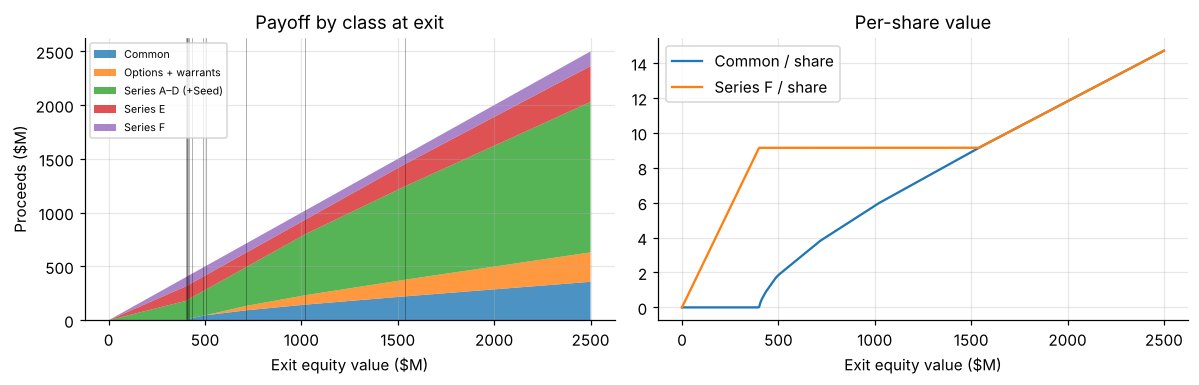

Breakpoints ($M): 399.8, 406.4, 407.1, 412.0, 415.1, 434.2, 487.1, 502.8, 713.8, 1,018.5, 1,539.5


In [3]:
bps, LP = breakpoints(ct)
V = np.linspace(1, 2.5e9, 600)
pays = [payoff(ct, v) for v in V]
grp = {'Common':[p['common'] for p in pays],'Options + warrants':[p['options']+p['warrants'] for p in pays],
       'Series A–D (+Seed)':[sum(p[s] for s in SERIES[:6]) for p in pays],'Series E':[p['E'] for p in pays],'Series F':[p['F'] for p in pays]}
fig, ax = plt.subplots(1,2, figsize=(11,3.6))
ax[0].stackplot(V/1e6, *[np.array(v)/1e6 for v in grp.values()], labels=grp.keys(), alpha=.8)
for b in bps: ax[0].axvline(b/1e6, color='k', lw=.4, alpha=.5)
ax[0].set_xlabel('Exit equity value ($M)'); ax[0].set_ylabel('Proceeds ($M)'); ax[0].legend(fontsize=7, loc='upper left'); ax[0].set_title('Payoff by class at exit')
ps = [p['common']/ct['common'] for p in pays]; pf = [p['F']/ct['pref'][7] for p in pays]
ax[1].plot(V/1e6, ps, label='Common / share'); ax[1].plot(V/1e6, pf, label='Series F / share')
ax[1].set_xlabel('Exit equity value ($M)'); ax[1].set_title('Per-share value'); ax[1].legend(); plt.tight_layout(); plt.show()
print('Breakpoints ($M):', ', '.join(f'{b/1e6:,.1f}' for b in bps))

Below $399.8M, preferred holders take everything pro rata to their preference. Common starts participating above that. Each series then converts in turn once the common value per share exceeds its issue price: Seed at $0.27 and Series F last, at $9.15, which corresponds to an exit of about $1.54B.

## 4. OPM backsolve to the preferred rounds

In [4]:
rows=[]; res={}
for d,(ser,px,rep,dl,r,T,sig) in BASE.items():
    c = cap_table(d); V0, vals, bps = backsolve(c, ser, px, T, r, sig); ps = per_share(c, vals)
    common_mkt = ps['common']; fv = common_mkt*(1-dl)
    res[d]=dict(V0=V0, common_mkt=common_mkt, fv=fv)
    rows.append([d, f'Series {ser} @ ${px}', T, sig, r, V0/1e6, sum(vals.values())/1e6, common_mkt, dl, fv, rep, fv/rep-1])
bs = pd.DataFrame(rows, columns=['Date','Calibrated to','T','σ','r','Backsolved equity ($M)','Σ classes ($M)','Common marketable','DLOM','Common FV','Reported','Error']).set_index('Date')
display(bs)

,Calibrated to,T,σ,r,Backsolved equity ($M),Σ classes ($M),Common marketable,DLOM,Common FV,Reported,Error
Date,,,,,,,,,,,
2019-08-15,Series E @ $5.9566,3.5000,0.5400,0.0144,663.7017,663.7017,3.5962,0.3000,2.5173,2.5100,0.0029
2020-08-05,Series F @ $9.1456,2.5000,0.5400,0.0016,932.7519,932.7519,4.7540,0.2500,3.5655,3.5400,0.0072


Both reported values are reproduced within **1%**, using one consistent set of inputs:
* **σ = 54%,** the top of the volatility range Remitly disclosed for its own option grants (2019: 53.8–54.0%). Early-stage OPM volatilities are normally at least as high as option-grant volatilities.
* **A single expected liquidity date of about Feb-2023,** giving T = 3.5 years from Aug-2019 and 2.5 years from Aug-2020. Assuming the same exit date at both valuations is what an auditor would want to see.
* **The company's own DLOM** (30% and 25%), which is tested in §6.

The backsolved equity value rises from $664M to $933M between the two rounds, which is consistent with the Series F step-up from $5.96 to $9.15.

## 5. Which inputs reproduce the reported value? (implied T × σ frontier)

<>:7: SyntaxWarning: invalid escape sequence '\$'
<>:7: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_550/341873482.py:7: SyntaxWarning: invalid escape sequence '\$'
  ax.scatter([s0*100],[T0], color='k', zorder=3); ax.set_xlabel('σ (%)'); ax.set_ylabel('T (years)'); ax.set_title(f'{d}: error vs reported \${rep}')


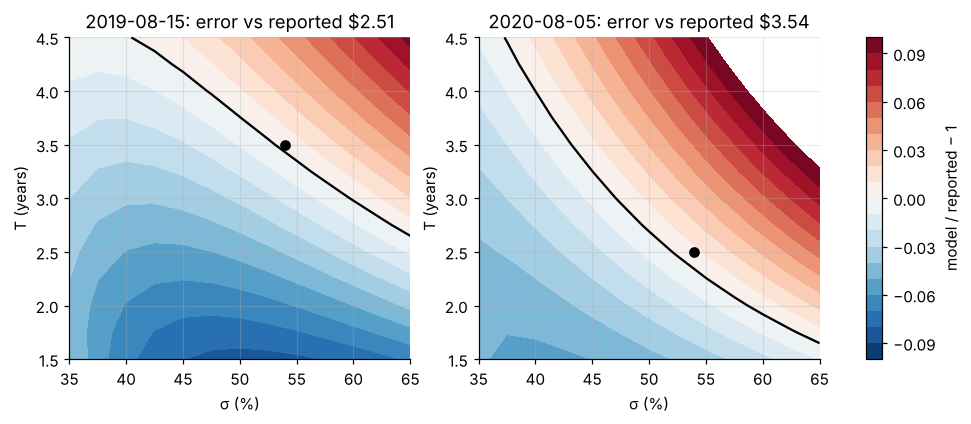

2019 option-strike sensitivity (common FV): {1.0: 2.5, 1.5: 2.517, 2.0: 2.531}


In [5]:
Ts = np.arange(1.5, 4.51, 0.25); sigs = np.arange(0.35, 0.651, 0.025)
fig, axs = plt.subplots(1,2, figsize=(11,3.8))
for ax,(d,(ser,px,rep,dl,r,T0,s0)) in zip(axs, BASE.items()):
    c = cap_table(d)
    G = np.array([[backsolve(c,ser,px,T,r,s)[1]['common']/c['common']*(1-dl) for s in sigs] for T in Ts])
    cs = ax.contourf(sigs*100, Ts, G/rep-1, levels=np.linspace(-.1,.1,21), cmap='RdBu_r'); ax.contour(sigs*100, Ts, G/rep-1, levels=[0], colors='k')
    ax.scatter([s0*100],[T0], color='k', zorder=3); ax.set_xlabel('σ (%)'); ax.set_ylabel('T (years)'); ax.set_title(f'{d}: error vs reported \${rep}')
plt.colorbar(cs, ax=axs, label='model / reported − 1'); plt.show()
c=cap_table('2019-08-15'); ser,px,rep,dl,r,T,s=BASE['2019-08-15']
sens_k = {k: backsolve({**c,'opt_k':k},ser,px,T,r,s)[1]['common']/c['common']*(1-dl) for k in [1.0,1.5,2.0]}
print('2019 option-strike sensitivity (common FV):', {k:round(v,3) for k,v in sens_k.items()})

The black line marks every (T, σ) pair that reproduces the reported value exactly, and the base case (dot) sits on or near it for both dates. Common value is fairly insensitive to the inputs: a ±10% error band covers most plausible combinations. This is typical of an OPM backsolve, because the preferred price anchors the whole structure. The estimated 2019 option strike moves the result by only about ±$0.02 across a strike range of $1.00–$2.00.

## 6. DLOM cross-check

,T,σ,Company DLOM,Finnerty,Chaffe (ATM put),FV @ Finnerty,FV @ Chaffe
Date,,,,,,,
2019-08-15,3.5000,0.5400,0.3000,0.2102,0.3529,2.8402,2.3271
2020-08-05,2.5000,0.5400,0.2500,0.1830,0.3279,3.8842,3.1952


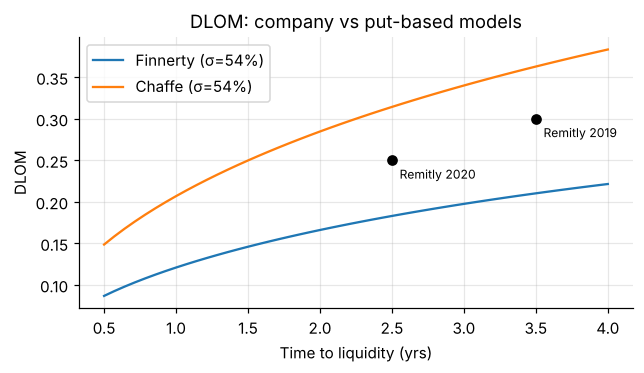

In [6]:
rows=[]
for d,(ser,px,rep,dl,r,T,sig) in BASE.items():
    rows.append([d, T, sig, dl, finnerty(T,sig), chaffe(T,r,sig), res[d]['common_mkt']*(1-finnerty(T,sig)), res[d]['common_mkt']*(1-chaffe(T,r,sig))])
dl = pd.DataFrame(rows, columns=['Date','T','σ','Company DLOM','Finnerty','Chaffe (ATM put)','FV @ Finnerty','FV @ Chaffe']).set_index('Date'); display(dl)
Tg=np.linspace(.5,4,50)
fig,ax=plt.subplots(figsize=(6.5,3.2))
ax.plot(Tg,[finnerty(t,.54) for t in Tg],label='Finnerty (σ=54%)'); ax.plot(Tg,[chaffe(t,.01,.54) for t in Tg],label='Chaffe (σ=54%)')
for d,(ser,px,rep,dlc,r,T,s) in BASE.items(): ax.scatter(T,dlc,color='k',zorder=3); ax.annotate(f'Remitly {d[:4]}',(T,dlc),textcoords='offset points',xytext=(5,-12),fontsize=8)
ax.set_xlabel('Time to liquidity (yrs)'); ax.set_ylabel('DLOM'); ax.legend(); ax.set_title('DLOM: company vs put-based models'); plt.show()

Remitly's 30% and 25% DLOMs sit between the Finnerty average-strike put (the low end) and the Chaffe protective put (the high end). This is where practitioners typically conclude, often by averaging the two or weighting them with restricted-stock studies. The DLOM is therefore supportable. Using Finnerty alone would raise the Aug-2020 common value to about $3.88, a difference an auditor would ask the preparer to justify.

## 7. The 31-Aug-2021 hybrid and the cheap-stock reconciliation
The disclosed structure is: 77.5% early IPO (DLOM 13.5%), 15% median IPO (16%) and 7.5% OPM delayed exit (25%). In the IPO scenarios all preferred converts, so common is worth the IPO price per share, discounted for time. Assumptions not disclosed by Remitly: a 20% discount rate, median IPO about 0.5 years out, and OPM T = 2 years with σ = 50% (the top of the 2021 option-vol range). The unknown is the IPO value the valuation expected, which is solved so the hybrid equals the reported $28.73.

Implied expected IPO value at 31-Aug-2021: $34.51 per share  (range set 10-Sep-2021: $38–42; priced 22-Sep-2021: $43)
Hybrid at the $40 midpoint: $33.30  ->  components {'early': np.float64(26.49), 'median': np.float64(4.56), 'opm': 2.25}


<>:9: SyntaxWarning: invalid escape sequence '\$'
<>:12: SyntaxWarning: invalid escape sequence '\$'
<>:14: SyntaxWarning: invalid escape sequence '\$'
<>:14: SyntaxWarning: invalid escape sequence '\$'
<>:9: SyntaxWarning: invalid escape sequence '\$'
<>:12: SyntaxWarning: invalid escape sequence '\$'
<>:14: SyntaxWarning: invalid escape sequence '\$'
<>:14: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_550/2749068983.py:9: SyntaxWarning: invalid escape sequence '\$'
  ax.bar(i,v,color='gray'); run=v; ax.text(i,v+0.6,f'\${v:.2f}',ha='center',fontsize=9)
/tmp/ipykernel_550/2749068983.py:12: SyntaxWarning: invalid escape sequence '\$'
  ax.bar(len(steps),28.73,color='gray'); ax.text(len(steps),29.3,'\$28.73',ha='center',fontsize=9)
/tmp/ipykernel_550/2749068983.py:14: SyntaxWarning: invalid escape sequence '\$'
  ax.set_title('Bridge: \$40 IPO midpoint to \$28.73 common FV (31-Aug-2021)'); ax.set_ylabel('\$ per share'); plt.tight_layout(); plt.show()
/tmp/ipykernel_550/2749

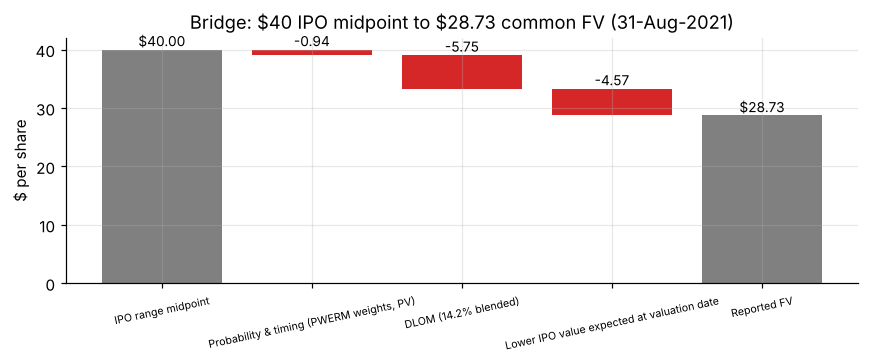

Implied IPO value by discount rate (cols) and median-IPO timing (rows):


,0.1500,0.2000,0.2500,0.3000
median t=0.25,34.1240,34.2667,34.4096,34.5526
0.5,34.3059,34.5072,34.7076,34.9072
0.75,34.4831,34.7392,34.9924,35.2427
1.0,34.6554,34.9628,35.2642,35.5598


In [7]:
P_imp = implied_ipo_price(28.73)
v40, comp40, mkt40 = hybrid(40.0, parts=True)
print(f"Implied expected IPO value at 31-Aug-2021: ${P_imp:.2f} per share  (range set 10-Sep-2021: $38–42; priced 22-Sep-2021: $43)")
print(f"Hybrid at the $40 midpoint: ${v40:.2f}  ->  components {({k:round(x,2) for k,x in comp40.items()})}")
steps = [('IPO range midpoint',40.0),('Probability & timing (PWERM weights, PV)',mkt40-40),('DLOM (14.2% blended)',v40-mkt40),('Lower IPO value expected at valuation date',28.73-v40)]
fig,ax=plt.subplots(figsize=(8,3.4)); run=0
for i,(lab,v) in enumerate(steps):
    if i==0:
        ax.bar(i,v,color='gray'); run=v; ax.text(i,v+0.6,f'\${v:.2f}',ha='center',fontsize=9)
    else:
        lo=min(run,run+v); ax.bar(i,abs(v),bottom=lo,color='C2' if v>0 else 'C3'); ax.text(i,max(run,run+v)+0.6,f'{v:+.2f}',ha='center',fontsize=9); run+=v
ax.bar(len(steps),28.73,color='gray'); ax.text(len(steps),29.3,'\$28.73',ha='center',fontsize=9)
ax.set_xticks(range(len(steps)+1)); ax.set_xticklabels([s[0] for s in steps]+['Reported FV'],fontsize=7,rotation=12)
ax.set_title('Bridge: \$40 IPO midpoint to \$28.73 common FV (31-Aug-2021)'); ax.set_ylabel('\$ per share'); plt.tight_layout(); plt.show()
grid = pd.DataFrame({k:[implied_ipo_price(28.73, h={**HYBRID_2021,'k':k,'median':{**HYBRID_2021['median'],'t':t}}) for t in [0.25,0.5,0.75,1.0]] for k in [0.15,0.20,0.25,0.30]}, index=['median t=0.25','0.5','0.75','1.0'])
print('Implied IPO value by discount rate (cols) and median-IPO timing (rows):'); display(grid)

In [8]:
P2c, hc = two_condition_solve()
v2, comp2, mkt2 = hybrid(P2c, parts=True, haircut=hc)
c21 = cap_table('2021-08-31')
print(f"Second calibration target: Remitly's disclosed blended DLOM 14.2% (our single-condition solution gives {1-hybrid(P_imp,parts=True)[0]/hybrid(P_imp,parts=True)[2]:.1%})")
print(f"Solving both conditions: implied IPO value ${P2c:.2f}/share; delayed-exit equity {1-hc:.0%} of IPO-implied value "
      f"(${equity_from_price(c21,P2c)*(1-hc)/1e9:.2f}B vs ${equity_from_price(c21,P2c)/1e9:.2f}B); blended DLOM {1-v2/mkt2:.1%}")

Second calibration target: Remitly's disclosed blended DLOM 14.2% (our single-condition solution gives 14.7%)
Solving both conditions: implied IPO value $36.07/share; delayed-exit equity 36% of IPO-implied value ($2.29B vs $6.41B); blended DLOM 14.2%


**Refinement with a second disclosed number.** With the delayed-exit scenario valued at the full IPO-implied equity, the blended DLOM comes out at 14.7%, above the 14.2% Remitly disclosed. So Remitly's delayed-exit scenario must have carried a lower value. Solving for the reported $28.73 and the 14.2% blended DLOM together gives an implied IPO value of about **$36.1**, with the delayed-exit equity at roughly a third of the IPO value. That is a plausible downside case. The implied IPO value therefore lies between **$34.5 and $36.1**, 10–14% below the $40 midpoint.

**Reconciliation.** $28.73 is consistent with an expected IPO value of about **$34.5–36.1 per share** at the valuation date. That is about 10–14% below the $40 midpoint of the range, which the banks set 10 days later. The bridge mirrors the four factors in Remitly's letter:

1. **Liquidity:** the DLOM takes off about $5.8.
2. **IPO probability:** the 92.5% PWERM weight, versus 100% implicit in the range, takes off about $0.9 together with timing.
3. **Preferences:** worth almost nothing at a ~$6B equity value; they appear only inside the OPM scenario.
4. **Valuation versus indication:** the residual of about $4.6 reflects the lower IPO value expected before the range was set.

Across reasonable discount rates and timing, the implied value stays at $34–36. An auditor would ask management to support it with the banks' August indications. The final $43 price, which came after a further three weeks of book-building, does not by itself make the Aug-31 value cheap stock.

## 8. Common stock value path

<>:5: SyntaxWarning: invalid escape sequence '\$'
<>:7: SyntaxWarning: invalid escape sequence '\$'
<>:5: SyntaxWarning: invalid escape sequence '\$'
<>:7: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_550/599296067.py:5: SyntaxWarning: invalid escape sequence '\$'
  ax.scatter(pd.to_datetime(['2021-09-22']),[43],marker='*',s=120,color='C3',label='IPO price \$43')
/tmp/ipykernel_550/599296067.py:7: SyntaxWarning: invalid escape sequence '\$'
  ax.set_ylabel('\$ per share'); ax.legend(fontsize=7); ax.set_title('Remitly common stock value path'); plt.show()


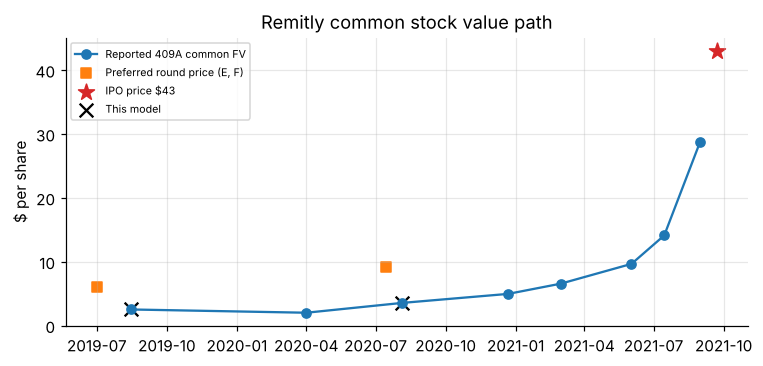

In [9]:
fv = pd.DataFrame({'date':pd.to_datetime(['2019-08-15','2020-04-01','2020-08-05','2020-12-22','2021-03-01','2021-06-02','2021-07-15','2021-08-31']),
                   'fv':[2.51,2.00,3.54,4.95,6.55,9.65,14.11,28.73]})
fig,ax=plt.subplots(figsize=(8,3.4)); ax.plot(fv.date,fv.fv,'o-',label='Reported 409A common FV')
ax.scatter(pd.to_datetime(['2019-07-01','2020-07-15']),[5.9566,9.1456],marker='s',color='C1',label='Preferred round price (E, F)')
ax.scatter(pd.to_datetime(['2021-09-22']),[43],marker='*',s=120,color='C3',label='IPO price \$43')
m = [res['2019-08-15']['fv'],res['2020-08-05']['fv']]; ax.scatter(pd.to_datetime(['2019-08-15','2020-08-05']),m,marker='x',s=80,color='k',label='This model')
ax.set_ylabel('\$ per share'); ax.legend(fontsize=7); ax.set_title('Remitly common stock value path'); plt.show()

## 9. Export for the Excel model

In [10]:
out = dict(implied_P2=P2c, haircut=hc, base={d:dict(V0=res[d]['V0'],common_mkt=res[d]['common_mkt'],fv=res[d]['fv']) for d in BASE},
           dlom=dl.reset_index().values.tolist(), implied_P=P_imp, hybrid40=v40, comp40=comp40, mkt40=mkt40,
           grid=grid.values.tolist(), grid_rows=list(grid.index), grid_cols=list(grid.columns))
json.dump(out, open('validation_results.json','w'), indent=1, default=float); print('saved')

saved


## 10. Conclusion and limitations
* **OPM backsolves.** Both reproduce Remitly's 409A values within 1% (2019: $2.52 vs $2.51; 2020: $3.57 vs $3.54), using σ = 54%, one expected exit date and the company's DLOM.
* **DLOMs.** They fall between the Finnerty and Chaffe estimates, so they are supportable.
* **Hybrid.** The Aug-2021 hybrid implies an expected IPO value of $34.5–36.1, which reconciles to the $40 midpoint through liquidity, probability, timing and a lower pre-range expectation.

*Limitations.* The option pool is modelled as one tranche. The 2019 option strike is estimated. Monthly-average Treasury rates are used for 2020–21. The PWERM discount rate and median-IPO timing are assumptions, and the S-1 does not disclose the company's actual scenario values.